In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve, RandomizedSearchCV
from sklearn.pipeline import Pipeline 
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance

In [3]:
X_train = pd.read_csv("../../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]      # regression target
y_clf = y_train["target_direction"]        # classification target (1 = next day up)
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


In [4]:
tscv = TimeSeriesSplit(n_splits=5)
REG_SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
CLF_SCORING = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

def cv_scores(model, y, task):
    scoring = REG_SCORING if task == "regression" else CLF_SCORING
    res = cross_validate(model, X_train, y, cv=tscv, scoring=scoring, n_jobs=-1)
    out = {"task": task}
    for k in scoring:
        v = res[f"test_{k}"]
        v = -v if k in ("rmse", "mae") else v
        out[k] = v.mean(); out[k + "_std"] = v.std()
    return out


def plot_curve(model, y, param, values, scoring, title, fname, flip=False):
    tr, va = validation_curve(model, X_train, y, param_name=param, param_range=values, cv=tscv, scoring=scoring, n_jobs=-1)
    s = -1 if flip else 1
    xs = np.arange(len(values)); labels = [str(v) for v in values]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for arr, name in ((s * tr, "train"), (s * va, "validation")):
        ax.plot(xs, arr.mean(1), marker="o", label=name)
        ax.fill_between(xs, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=0.15)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_xlabel(param); ax.set_title(title); ax.legend()
    plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/" + fname, dpi=130); plt.show()
    return pd.DataFrame({"value": labels, "train": (s * tr).mean(1), "validation": (s * va).mean(1)})

In [5]:
reg = Pipeline([("model", RandomForestRegressor(n_estimators=200, max_depth=6, min_samples_leaf=20, max_features=0.5, n_jobs=1, random_state=42))])
clf = Pipeline([("model", RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=20, max_features=0.5, n_jobs=1, random_state=42))])
r_reg = cv_scores(reg, y_reg, "regression"); r_clf = cv_scores(clf, y_clf, "classification")
print({k: round(v, 4) for k, v in r_reg.items() if k != "task"}); print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

{'rmse': np.float64(0.0503), 'rmse_std': np.float64(0.0154), 'mae': np.float64(0.037), 'mae_std': np.float64(0.0112), 'r2': np.float64(-0.0364), 'r2_std': np.float64(0.027)}
{'accuracy': np.float64(0.5111), 'accuracy_std': np.float64(0.0182), 'f1': np.float64(0.5276), 'f1_std': np.float64(0.0812), 'roc_auc': np.float64(0.508), 'roc_auc_std': np.float64(0.02)}


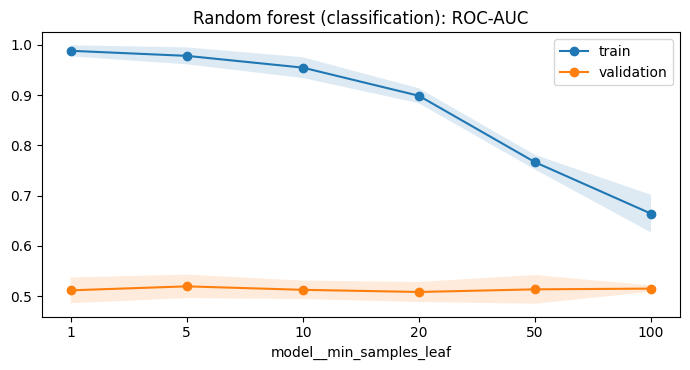

,value,train,validation
0,1,0.988,0.511
1,5,0.978,0.519
2,10,0.955,0.512
3,20,0.899,0.508
4,50,0.766,0.513
5,100,0.664,0.515


In [6]:
leaves = [1, 5, 10, 20, 50, 100]
l_clf = plot_curve(clf, y_clf, "model__min_samples_leaf", leaves, "roc_auc", "Random forest (classification): ROC-AUC", "rf_leaf_clf.png")
l_clf.round(3)

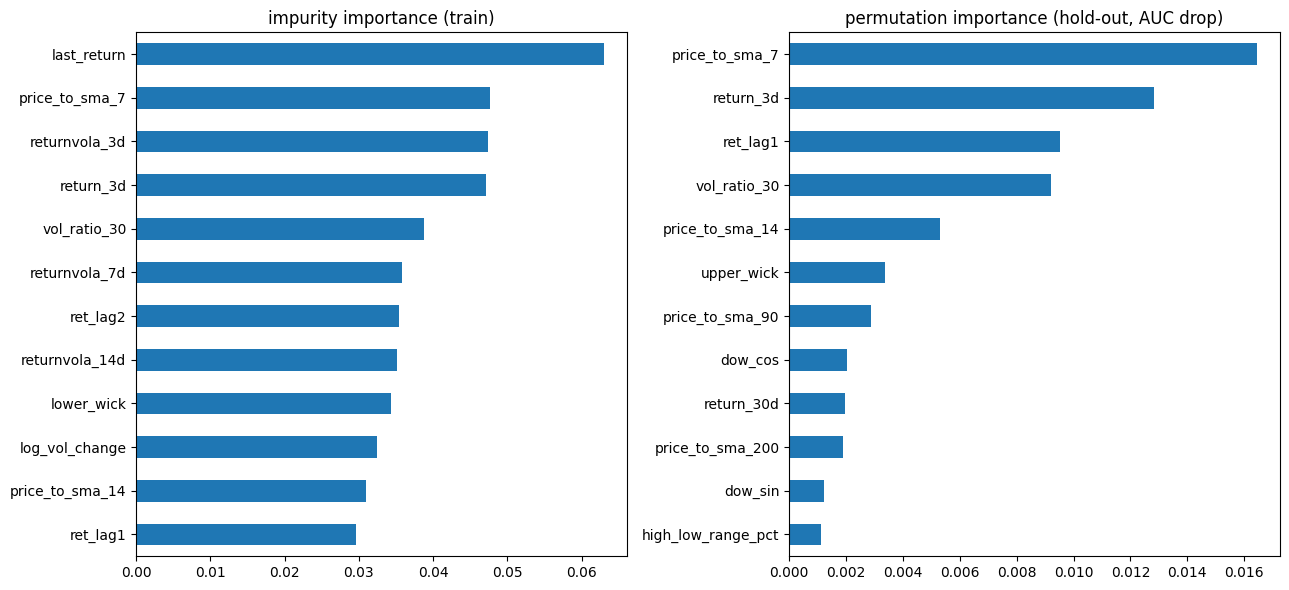

In [7]:
cut = int(len(X_train) * 0.8)
Xa, Xb, ya, yb = X_train.iloc[:cut], X_train.iloc[cut:], y_clf.iloc[:cut], y_clf.iloc[cut:]
m = clf.fit(Xa, ya)
imp_tree = pd.Series(m.named_steps["model"].feature_importances_, index=X_train.columns)
perm = permutation_importance(m, Xb, yb, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_train.columns)
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
imp_tree.sort_values().tail(12).plot.barh(ax=ax[0], title="impurity importance (train)")
imp_perm.sort_values().tail(12).plot.barh(ax=ax[1], title="permutation importance (hold-out, AUC drop)")
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/rf_importance.png", dpi=130); plt.show()

In [8]:
rows0 = [{"model": "RandomForestRegressor", "task": "regression", **r_reg}, {"model": "RandomForestClassifier", "task": "classification", **r_clf}]
results = pd.DataFrame(rows0)
results.to_csv("../../03.results/outputs/rf_results.csv", index=False)

In [9]:
#import finetuning model
from sklearn.model_selection import RandomizedSearchCV

In [10]:
param_distributions = {
    "n_estimators": [200, 400, 600],
    "max_depth": [None, 4, 6, 8, 12],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 5, 10, 20, 40],
    "max_features": [0.5, 0.75, 1.0],
    "bootstrap": [True]
}

In [11]:
reg_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=20, cv=tscv, scoring="neg_root_mean_squared_error",
    random_state=42, n_jobs=-1, refit=True
)

In [12]:
clf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=20, cv=tscv, scoring="roc_auc",
    random_state=42, n_jobs=-1, refit=True
)

In [13]:
reg_search.fit(X_train, y_reg)
clf_search.fit(X_train, y_clf)
reg = Pipeline([("model", reg_search.best_estimator_)])
clf = Pipeline([("model", clf_search.best_estimator_)])

In [14]:
r_reg = cv_scores(reg, y_reg, "regression")
r_clf = cv_scores(clf, y_clf, "classification")

In [15]:
print("Best regression parameters:", reg_search.best_params_)
print("Best classification parameters:", clf_search.best_params_)
print({k: round(v, 4) for k, v in r_reg.items() if k != "task"})
print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

Best regression parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 40, 'max_features': 0.5, 'max_depth': 4, 'bootstrap': True}
Best classification parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None, 'bootstrap': True}
{'rmse': np.float64(0.0498), 'rmse_std': np.float64(0.015), 'mae': np.float64(0.0366), 'mae_std': np.float64(0.0108), 'r2': np.float64(-0.0207), 'r2_std': np.float64(0.0141)}
{'accuracy': np.float64(0.5172), 'accuracy_std': np.float64(0.02), 'f1': np.float64(0.5155), 'f1_std': np.float64(0.0724), 'roc_auc': np.float64(0.5249), 'roc_auc_std': np.float64(0.0218)}


In [16]:
rows = [{"model": "Random Forest", **r_reg}, {"model": "Random Forest", **r_clf}]
res = pd.DataFrame(rows)
res.to_csv("../../03.results/logs/model_results_random_forest.csv", index=False)
res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,Random Forest,regression,0.0498,0.015,0.0366,0.0108,-0.0207,0.0141,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest,classification,NaN,NaN,NaN,NaN,NaN,NaN,0.5172,0.02,0.5155,0.0724,0.5249,0.0218
